In [1]:
from pathlib import Path
import json
import pandas as pd

In [17]:
RETRIEVAL_DIR = Path(f"../output/retrieval")
DATA_DIR = Path("../data/gold_data")

RESULTS_DIR = Path("../results/retrieval")
RESULTS_DIR.mkdir(parents=False, exist_ok=True)

METHOD = "bm25" # "hybrid" # "dense"

In [12]:
retrieval_files = list((RETRIEVAL_DIR/METHOD).rglob("*.json"))

gold_processed_df = pd.read_csv(DATA_DIR / "gold_standard_processed.csv")
print(f"Gold before filtering NA: {len(gold_processed_df)}")
gold_processed_df.dropna(inplace=True)
print(f"Gold after filtering NA: {len(gold_processed_df)}")

Gold before filtering NA: 582
Gold after filtering NA: 510


C:\Users\Marvin.Klein\AppData\Local\Temp\ipykernel_2028\342075856.py:5: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  gold_processed_df.dropna(inplace=True)


In [14]:
gold_pages_by_report = gold_processed_df.groupby("report_id")["page"].agg(set).to_dict()
gold_pages_by_report

{'Allianz_2022': {79.0},
 'Daimler_2020': {63.0},
 'Fresenius SE_2019': {126.0},
 'acuity brands inc_2022': {99.0, 101.0},
 'addtech_2022': {73.0},
 'aixtron_2020': {51.0},
 'allfunds group_2021': {125.0, 142.0},
 'americold realty inc_2022': {53.0},
 'arteria networks corp_2019': {10.0},
 'autoneum holding_2019': {27.0},
 'balanced commercial property trust_2020': {34.0},
 'bekaert (d) sa_2022': {276.0},
 'blackberry ltd_2022': {21.0, 22.0},
 'blackline inc_2021': {21.0},
 'cabot corp_2018': {22.0},
 'cardinal energy ltd_2021': {19.0},
 'century communities inc_2019': {11.0},
 'chase corp_2020': {32.0},
 'comerica inc_2019': {44.0},
 'cubesmart reit_2021': {19.0},
 'cytokinetics inc_2022': {24.0},
 'dampskibsselskabet norden_2019': {63.0},
 'dksh holding_2021': {73.0, 74.0},
 'evolution mining ltd_2020': {44.0},
 'fabege_2022': {45.0},
 'fastly inc_2018': {43.0},
 'freni brembo_2018': {131.0},
 'fuji soft inc_2022': {80.0, 81.0},
 'georg fischer ag_2018': {17.0},
 'granite constructio

In [15]:
results = []

for retrieval_file in retrieval_files:
    # if retrieval_file.stem.split("_")[0] != "amano corp":
    #     continue
    with open(retrieval_file, "r", encoding="utf-8") as f:
        rdata = json.load(f)
    
    
    retrieval_method = rdata.get("method")
    
    report_id = rdata.get("report_id") # report_name
    if report_id not in gold_pages_by_report:
        # raise ValueError(f"Skipping {retrieval_file.name}: no gold standard for report_id {report_id}.")
        continue
    
    retrieved_results = rdata.get("items", [])
    retrieved_pages = set()
    
    for item in retrieved_results:
        metadata = item.get("metadata", {})
        page_numbers = metadata.get("page_no")
        #retrieved_pages.update(page_numbers)
        retrieved_pages.add(page_numbers)
    
    gold_pages = gold_pages_by_report[report_id]
    
    # Evaluate retrieval results
    true_positives = len(retrieved_pages & gold_pages)
    false_positives = len(retrieved_pages - gold_pages)
    false_negatives = len(gold_pages - retrieved_pages)
    
    precision = true_positives / (true_positives + false_positives) if (true_positives + false_positives) > 0 else 0
    recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0
    f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    results.append({
        "report_id": report_id,
        "precision": precision,
        "recall": recall,
        "f1_score": f1_score
    })
 
print(f"Retrieval Method: {retrieval_method}")
df = pd.DataFrame(results)
#df.to_csv(f"{RESULTS_PATH}/{retrieval_method}_instruct_retrieval_eval_with_top6.csv", index=False)

df

Retrieval Method: bm25


,report_id,precision,recall,f1_score
0,acuity brands inc_2022,0.4,1.000000,0.571429
1,addtech_2022,0.2,1.000000,0.333333
2,aixtron_2020,0.2,1.000000,0.333333
3,allfunds group_2021,0.4,1.000000,0.571429
4,Allianz_2022,0.2,1.000000,0.333333
...,...,...,...,...
58,the simply good foods company_2018,0.2,1.000000,0.333333
59,toshiba tec corp_2022,0.2,1.000000,0.333333
60,uniper_2019,0.4,0.666667,0.500000
61,varta ag_2021,0.2,1.000000,0.333333


In [16]:
df["precision"].mean(), df["recall"].mean(), df["f1_score"].mean()

(np.float64(0.22539682539682535),
 np.float64(0.9788359788359788),
 np.float64(0.3609221466364324))

In [38]:
import bm25s
import Stemmer

stemmer = Stemmer.Stemmer("english")
#token_pattern = r"(?u)\b\w+\b"


# Your keyword list
keyword_query = """greenhouse gas greenhouse gases ghg ghgs emission emissions emit 
        emitted carbon emissions carbon footprint carbon dioxide equivalent co2 co2e co2 equivalent scope 1 
        direct emissions scope 2 indirect emissions location-based market-based purchased 
        electricity purchased energy scope 3 upstream emissions downstream emissions value chain 
        emissions total ghg emissions absolute emissions gross emissions ghg emissions intensity tco2e tonnes 
        co2e metric tonnes kilotonnes million tonnes ghg protocol emissions inventory global warming potential 
        gwp biogenic emissions base year emissions emissions reduction location based market based"""

# Query processing: matches _retrieve()
query_tokens = bm25s.tokenize(
    keyword_query,
    stemmer=stemmer,
    #token_pattern=token_pattern
)

query_tokens.vocab

{'emit': 0,
 'million': 1,
 'tco2e': 2,
 'year': 3,
 'carbon': 4,
 'market': 5,
 'upstream': 6,
 'base': 7,
 'gwp': 8,
 'metric': 9,
 'co2': 10,
 'footprint': 11,
 'electr': 12,
 'locat': 13,
 'energi': 14,
 'tonn': 15,
 'kilotonn': 16,
 'emiss': 17,
 'greenhous': 18,
 'valu': 19,
 'total': 20,
 'ghg': 21,
 'co2e': 22,
 'intens': 23,
 'equival': 24,
 'inventori': 25,
 'gas': 26,
 'purchas': 27,
 'global': 28,
 'gross': 29,
 'dioxid': 30,
 'biogen': 31,
 'indirect': 32,
 'direct': 33,
 'absolut': 34,
 'warm': 35,
 'reduct': 36,
 'ghgs': 37,
 'protocol': 38,
 'gase': 39,
 'chain': 40,
 'downstream': 41,
 'potenti': 42,
 'scope': 43}

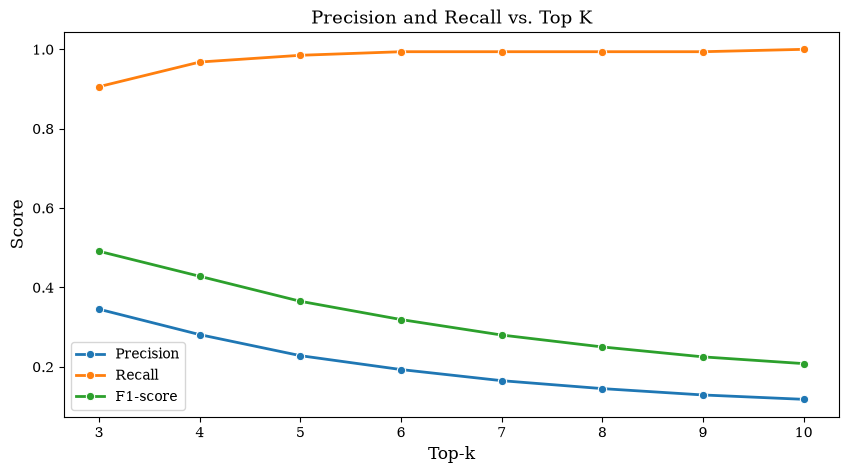

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

top_k_data = {
    "top_k": [3,4,5,6,7,8,9,10],
    "Precision": [0.345, 0.281, 0.228, 0.193, 0.165, 0.145, 0.129, 0.118],
    "Recall": [0.906, 0.968, 0.985, 0.994, 0.994, 0.994, 0.994, 1.0],
    "F1-score": [0.491, 0.428, 0.365, 0.319, 0.280, 0.250, 0.225, 0.208]
}

top_k_df = pd.DataFrame(top_k_data)

fig = plt.figure(figsize=(10, 5))
sns.lineplot(data=top_k_df, x="top_k", y="Precision", marker="o", label="Precision")
sns.lineplot(data=top_k_df, x="top_k", y="Recall", marker="o", label="Recall")
sns.lineplot(data=top_k_df, x="top_k", y="F1-score", marker="o", label="F1-score")
plt.title("Precision and Recall vs. Top K")
plt.xlabel("Top-k")
plt.ylabel("Score")
plt.legend()
plt.show()
# save plot
fig.savefig("top_k_retrieval_performance.pdf")

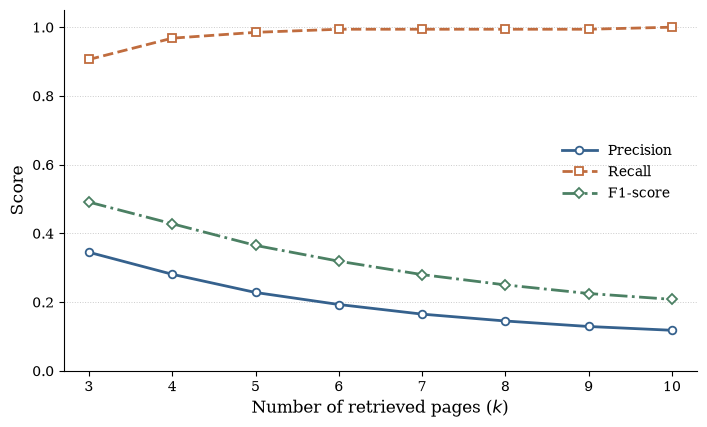

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

top_k_data = {
    "top_k": [3, 4, 5, 6, 7, 8, 9, 10],
    "Precision": [0.345, 0.281, 0.228, 0.193, 0.165, 0.145, 0.129, 0.118],
    "Recall": [0.906, 0.968, 0.985, 0.994, 0.994, 0.994, 0.994, 1.0],
    "F1-score": [0.491, 0.428, 0.365, 0.319, 0.280, 0.250, 0.225, 0.208],
}

top_k_df = pd.DataFrame(top_k_data)

# Academic publication style
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.linewidth": 0.8,
    "lines.linewidth": 2.0,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax = plt.subplots(figsize=(7.2, 4.4))

# Muted colors, distinct line styles, and hollow markers
styles = {
    "Precision": {
        "color": "#35618D",
        "linestyle": "-",
        "marker": "o",
    },
    "Recall": {
        "color": "#C06C3E",
        "linestyle": "--",
        "marker": "s",
    },
    "F1-score": {
        "color": "#4B8063",
        "linestyle": "-.",
        "marker": "D",
    },
}

for metric, style in styles.items():
    ax.plot(
        top_k_df["top_k"],
        top_k_df[metric],
        label=metric,
        linewidth=2.0,
        markersize=5.5,
        markerfacecolor="white",
        markeredgewidth=1.3,
        zorder=3,
        **style,
    )

# Axis formatting
ax.set_xlabel(r"Number of retrieved pages ($k$)")
ax.set_ylabel("Score")
ax.set_xlim(2.7, 10.3)
ax.set_ylim(0, 1.05)
ax.set_xticks(top_k_df["top_k"])
ax.yaxis.set_major_locator(MultipleLocator(0.2))

# Subtle horizontal gridlines
ax.grid(
    axis="y",
    linestyle=":",
    linewidth=0.7,
    alpha=0.65,
)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Compact legend without a frame
ax.legend(
    frameon=False,
    loc="center right",
    bbox_to_anchor=(0.98, 0.55),
    handlelength=2.5,
)

fig.tight_layout()

# Save publication-ready files without displaying the figure
# fig.savefig("top_k_retrieval_performance.pdf")
# fig.savefig("top_k_retrieval_performance.png", dpi=600)
# plt.close(fig)
plt.show()